## Automating National Briefings
Author: Smitha Mahesh, Eric Englin, Sophie Son

Purpose: To complete the analyses and visualizations required for the program-level briefings. 

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import docx

C:\Users\Sophie.Kaye\Anaconda3\lib\site-packages\scipy\__init__.py:138: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.4)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion} is required for this version of "


In [2]:
myworkingdirectory = r"C:\Users\Sophie.Kaye\Desktop\NPS Crash Data"
os.chdir(myworkingdirectory)

In [3]:
analysis_2024 = pd.read_csv("analysis_database_2024.csv")

<ipython-input-3-4fc69a7596d0>:1: DtypeWarning: Columns (68) have mixed types. Specify dtype option on import or set low_memory=False.
  analysis_2024 = pd.read_csv("analysis_database_2024.csv")


In [4]:
analysis_2024.shape

(218593, 71)

In [5]:
analysis_2024.columns

Index(['INCID_NO', '5_mph', '10_mph', '15_mph', '20_mph', '25_mph', '30_mph',
       '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph', '65_mph',
       '70_mph', '75_mph', 'no_posted_speed', 'Crosswalk',
       'Outside a Crosswalk', 'NUM_VEH', 'Num_Motorcycle', 'Pax', 'SUV', 'Van',
       'Bus', 'Medium Truck', 'Heavy Truck', 'Equipment', 'Nonroad HighSpeed',
       'Nonroad LowSpeed', 'Unknown', 'Motorcycle_Ind', 'No Injury',
       'Possible Injury', 'Non-incapacitating Injury', 'Incapacitating Injury',
       'Fatality', 'Num_Motorist', 'Num_Non_Motorist', 'Num_Pedestrian',
       'Num_Ped_Deaths', 'Pedestrian', 'VRU', 'Crash_Severity',
       'CrashSeverity_Fatal', 'CrashSeverity_Incap', 'CrashSeverity_NonIncap',
       'CrashSeverity_Possible', 'CrashSeverity_NoInj', 'First_Harmful_Event',
       'First_Harmful_Event_Type', 'Involving Animal', 'Daylight', 'Dawn',
       'Dusk', 'Dark_Lit', 'Dark_NotLit', 'Dark_UnknownLit',
       'UnknownBlankNullLit', 'Poor Lighting', 

In [6]:
imars = analysis_2024.loc[analysis_2024['database']=='IMARS']
cds = analysis_2024.loc[analysis_2024['database']=='CDS']

In [9]:
# the number of crash reports missing coordinates (could not be mapped) from cds is:
cds.loc[cds['LATITUDE'].isnull()].shape[0]

148441

In [10]:
# the percent of crash reports missing coordinates (could not be mapped) from cds is:
round(cds.loc[cds['LATITUDE'].isnull()].shape[0]/cds.shape[0]*100,1)

76.4

In [11]:
# the number of crash reports missing coordinates (could not be mapped) from imars is:
imars.loc[imars['LATITUDE'].isnull()].shape[0]

11511

In [12]:
# the percent of crash reports missing coordinates (could not be mapped) from imars is:
round(imars.loc[imars['LATITUDE'].isnull()].shape[0]/imars.shape[0]*100,1)

47.4

In [13]:
# for a total of:
148441+11511

159952

In [14]:
round(159952/analysis_2024.shape[0]*100,1)

73.2

# National Data Trends 

## Table 1:  Servicewide Fatal and Injury Crash Types (1990-2024 from CDS & IMARS) 

### national VRU crash stats 

In [15]:
vru = analysis_2024.loc[analysis_2024['VRU']==1]
vru_total_crashes = vru.shape[0]
vru_percent = round(vru.shape[0]/analysis_2024.shape[0]*100,2)
vru_serious_injury = int(vru['Incapacitating Injury'].sum())
vru_fatals = int(vru['Fatality'].sum())
vru_inj_or_fatal_percent = round((vru['CrashSeverity_Fatal'].sum()+vru['CrashSeverity_Incap'].sum())/vru.shape[0]*100,2)

print(vru_total_crashes,"number of crash reports involving VRUs")
print(vru_percent, "% of total crashes involving VRUs")
print(vru_serious_injury, "serious injuries in VRU crashes")
print(vru_fatals, "fatalities in VRU crashes")
print(vru_inj_or_fatal_percent, "% of VRU crashes resulting in a serious injury or fatality")

2182 number of crash reports involving VRUs
1.0 % of total crashes involving VRUs
393 serious injuries in VRU crashes
52 fatalities in VRU crashes
19.02 % of VRU crashes resulting in a serious injury or fatality


### national wildlife crash stats 

In [16]:
animal = analysis_2024.loc[analysis_2024['Involving Animal']==1]
animal_total_crashes = animal.shape[0]
animal_percent = round(animal.shape[0]/analysis_2024.shape[0]*100,2)
animal_serious_injury = int(animal['Incapacitating Injury'].sum())
animal_fatals = int(animal['Fatality'].sum())
animal_inj_or_fatal_percent = round((animal['CrashSeverity_Fatal'].sum()+animal['CrashSeverity_Incap'].sum())/animal.shape[0]*100,2)

print(animal_total_crashes,"number of crash reports involving wildlife")
print(animal_percent, "% of total crashes involving wildlife")
print(animal_serious_injury, "serious injuries in wildlife crashes")
print(animal_fatals, "fatalities in wildlife crashes")
print(animal_inj_or_fatal_percent, "% of wildlife crashes resulting in a serious injury or fatality")

23747 number of crash reports involving wildlife
10.86 % of total crashes involving wildlife
355 serious injuries in wildlife crashes
32 fatalities in wildlife crashes
1.41 % of wildlife crashes resulting in a serious injury or fatality


### total national crash stats 

In [17]:
total_crashes = analysis_2024.shape[0]
total_serious_injury = int(analysis_2024['Incapacitating Injury'].sum())
total_fatals = int(analysis_2024['Fatality'].sum())
inj_or_fatal_percent = round((analysis_2024['CrashSeverity_Fatal'].sum()+analysis_2024['CrashSeverity_Incap'].sum())/analysis_2024.shape[0]*100,2)

print("total number of crash reports:", total_crashes)
print("total number of serious injuries:", total_serious_injury)
print("total number of fatalities:", total_fatals)
print("% of total crashes resulting in an injury or fatality:", inj_or_fatal_percent)

total number of crash reports: 218593
total number of serious injuries: 8779
total number of fatalities: 1448
% of total crashes resulting in an injury or fatality: 3.78


### assemble table

In [18]:
nationaldata= {'Collision Type': ['Crashes Involving VRUs','Crashes Involving Wildlife', 'All Crashes'], 'Number of Crash Reports': [vru_total_crashes, animal_total_crashes, total_crashes], 'Percentage of Total Crashes': [vru_percent, animal_percent, 100.00], 'Number of Serious Injuries':[vru_serious_injury, animal_serious_injury, total_serious_injury], 'Number of Fatalities':[vru_fatals, animal_fatals, total_fatals], 'Percent of Crashes Resulting in an Injury/Fatality':[vru_inj_or_fatal_percent, animal_inj_or_fatal_percent, inj_or_fatal_percent]}
df5 = pd.DataFrame(nationaldata)
print(df5)

               Collision Type  Number of Crash Reports  \
0      Crashes Involving VRUs                     2182   
1  Crashes Involving Wildlife                    23747   
2                 All Crashes                   218593   

   Percentage of Total Crashes  Number of Serious Injuries  \
0                         1.00                         393   
1                        10.86                         355   
2                       100.00                        8779   

   Number of Fatalities  Percent of Crashes Resulting in an Injury/Fatality  
0                    52                                              19.02   
1                    32                                               1.41   
2                  1448                                               3.78   


## Figure 1: All Crashes By Speed Limit

In [15]:
speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
fatalities = []
serious_injuries = []
crashes = []

for i in speed_columns:
    num_fatalities = analysis_2024.loc[analysis_2024[i]==1]['Fatality'].sum()
    fatalities.append(num_fatalities)
    num_serious_injuries = analysis_2024.loc[analysis_2024[i]==1]['Incapacitating Injury'].sum()
    serious_injuries.append(num_serious_injuries)    
    num_crashes = analysis_2024.loc[analysis_2024[i]==1].shape[0]
    crashes.append(num_crashes)

<ipython-input-16-f02ac5d9bf31>:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


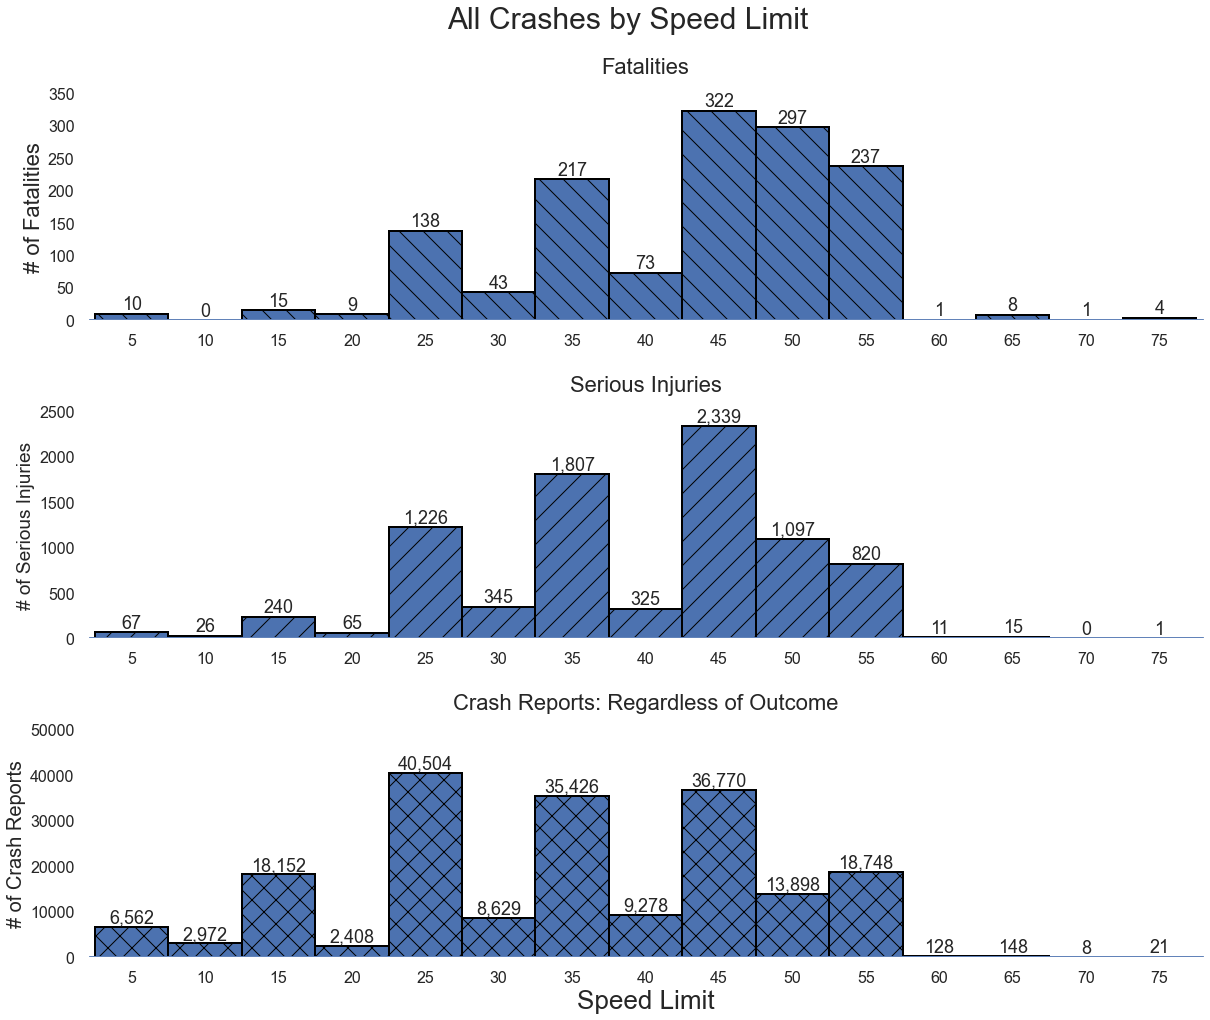

In [16]:
# set up main figure with three subplots
plt.style.use('seaborn')
sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
fig, ax = plt.subplots(3,1,figsize=(20,15))
tick_spacing = 5
fig.suptitle('All Crashes by Speed Limit', fontsize=30)

# subplot data
ax[0].bar(speed_list, fatalities, width = 5, hatch = "\\", edgecolor = "black", linewidth=2)
ax[1].bar(speed_list, serious_injuries, width = 5, hatch = "/", edgecolor = "black", linewidth=2)
ax[2].bar(speed_list, crashes, width = 5, hatch = "x", edgecolor = "black", linewidth=2)

# annotate all plots with bar totals
rects = ax[0].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[0].text(rect.get_x() + rect.get_width() / 2, height + 0.5, label, ha="center", va="bottom",fontsize=18)

rects = ax[1].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[1].text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha="center", va="bottom",fontsize=18)

rects = ax[2].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[2].text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha="center", va="bottom",fontsize=18)

# format each subplot
ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
ax[0].set_ylim([0, 350])
ax[0].set_xlim([2, 78])
ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
ax[0].tick_params(axis='x', which='major', labelsize=16)
ax[0].tick_params(axis='y', which='major', labelsize=16)
ax[0].tick_params(axis='both', which='minor', labelsize=8)

ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
ax[1].set_ylim([0, 2500])
ax[1].set_xlim([2, 78])
ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
ax[1].tick_params(axis='x', which='major', labelsize=16)
ax[1].tick_params(axis='y', which='major', labelsize=16)
ax[1].tick_params(axis='both', which='minor', labelsize=8)

ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
ax[2].set_ylim([0, 50000])
ax[2].set_xlim([2, 78])
ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
ax[2].tick_params(axis='x', which='major', labelsize=16)
ax[2].tick_params(axis='y', which='major', labelsize=16)
ax[2].tick_params(axis='both', which='minor', labelsize=8)

# set the spacing between subplots
plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

plt.show()

## Figure 2: Crashes Resulting in an Injury or Fatality

In [22]:
speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
seriousinjury = analysis_2024.loc[analysis_2024['CrashSeverity_Fatal']>0]
fatal = analysis_2024.loc[analysis_2024['CrashSeverity_Incap']>0]
inj_or_fatal = pd.concat([seriousinjury,fatal])
vru_inj_or_fatal = inj_or_fatal.loc[inj_or_fatal['VRU']==1]
animal_inj_or_fatal = inj_or_fatal.loc[inj_or_fatal['Involving Animal']==1]
VRU_crashes = []
wildlife_crashes = []
all_crashes = []

for i in speed_columns:
    num_VRU_crashes = vru_inj_or_fatal.loc[vru_inj_or_fatal[i]==1].shape[0]
    VRU_crashes.append(num_VRU_crashes)
    num_wildlife_crashes = animal_inj_or_fatal.loc[animal_inj_or_fatal[i]==1].shape[0]
    wildlife_crashes.append(num_wildlife_crashes)    
    num_all_crashes = inj_or_fatal.loc[inj_or_fatal[i]==1].shape[0]
    all_crashes.append(num_all_crashes)

<ipython-input-23-8189be191145>:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


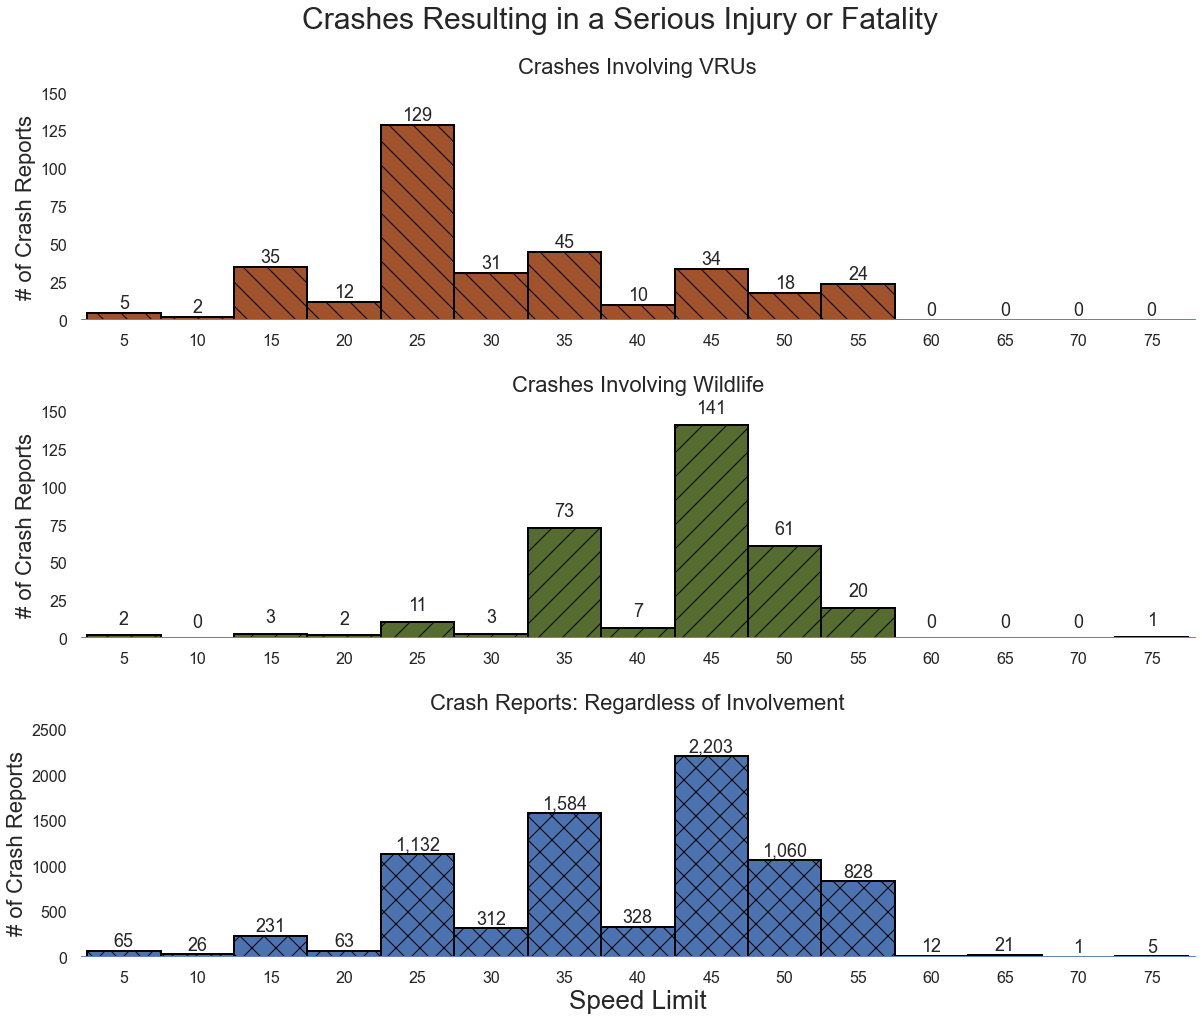

In [23]:
# set up main figure with three subplots
plt.style.use('seaborn')
sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
fig, ax = plt.subplots(3,1,figsize=(20,15))
tick_spacing = 5
fig.suptitle('Crashes Resulting in a Serious Injury or Fatality', fontsize=30)

# subplot data
ax[0].bar(speed_list, VRU_crashes, width = 5, hatch = "\\", color = 'sienna', edgecolor = "black", linewidth=2)
ax[1].bar(speed_list, wildlife_crashes, width = 5, hatch = "/", color = 'darkolivegreen', edgecolor = "black", linewidth=2)
ax[2].bar(speed_list, all_crashes, width = 5, hatch = "x", edgecolor = "black", linewidth=2)

# annotate all plots with bar totals
rects = ax[0].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[0].text(rect.get_x() + rect.get_width() / 2, height + 0.5, label, ha="center", va="bottom",fontsize=18)

rects = ax[1].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[1].text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha="center", va="bottom",fontsize=18)

rects = ax[2].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[2].text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha="center", va="bottom",fontsize=18)

# format each subplot
ax[0].set_title("Crashes Involving VRUs",fontsize= 22, pad = 20)
ax[0].set_ylim([0, 150])
ax[0].set_xlim([2, 78])
ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[0].set_ylabel("# of Crash Reports", fontsize = 22)#ylabel
ax[0].tick_params(axis='x', which='major', labelsize=16)
ax[0].tick_params(axis='y', which='major', labelsize=16)
ax[0].tick_params(axis='both', which='minor', labelsize=8)

ax[1].set_title("Crashes Involving Wildlife",fontsize= 22, pad = 20)
ax[1].set_ylim([0, 150])
ax[1].set_xlim([2, 78])
ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[1].set_ylabel("# of Crash Reports", fontsize = 22)#ylabel
ax[1].tick_params(axis='x', which='major', labelsize=16)
ax[1].tick_params(axis='y', which='major', labelsize=16)
ax[1].tick_params(axis='both', which='minor', labelsize=8)

ax[2].set_title("Crash Reports: Regardless of Involvement",fontsize= 22, pad = 20)
ax[2].set_ylim([0, 2500])
ax[2].set_xlim([2, 78])
ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
ax[2].set_ylabel("# of Crash Reports", fontsize = 22)#ylabel
ax[2].tick_params(axis='x', which='major', labelsize=16)
ax[2].tick_params(axis='y', which='major', labelsize=16)
ax[2].tick_params(axis='both', which='minor', labelsize=8)

# set the spacing between subplots
plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

plt.show()

## Figure 3: VRU Crashes By Speed Limit

In [4]:
speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
vru = analysis_2024.loc[analysis_2024['VRU']==1]
vru_fatalities = []
vru_serious_injuries = []
vru_crashes = []

for i in speed_columns:
    num_vru_fatalities = vru.loc[vru[i]==1]['Fatality'].sum()
    vru_fatalities.append(num_vru_fatalities)
    num_vru_serious_injuries = vru.loc[vru[i]==1]['Incapacitating Injury'].sum()
    vru_serious_injuries.append(num_vru_serious_injuries)    
    num_vru_crashes = vru.loc[vru[i]==1].shape[0]
    vru_crashes.append(num_vru_crashes)

<ipython-input-5-8cc98c4c4cd3>:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


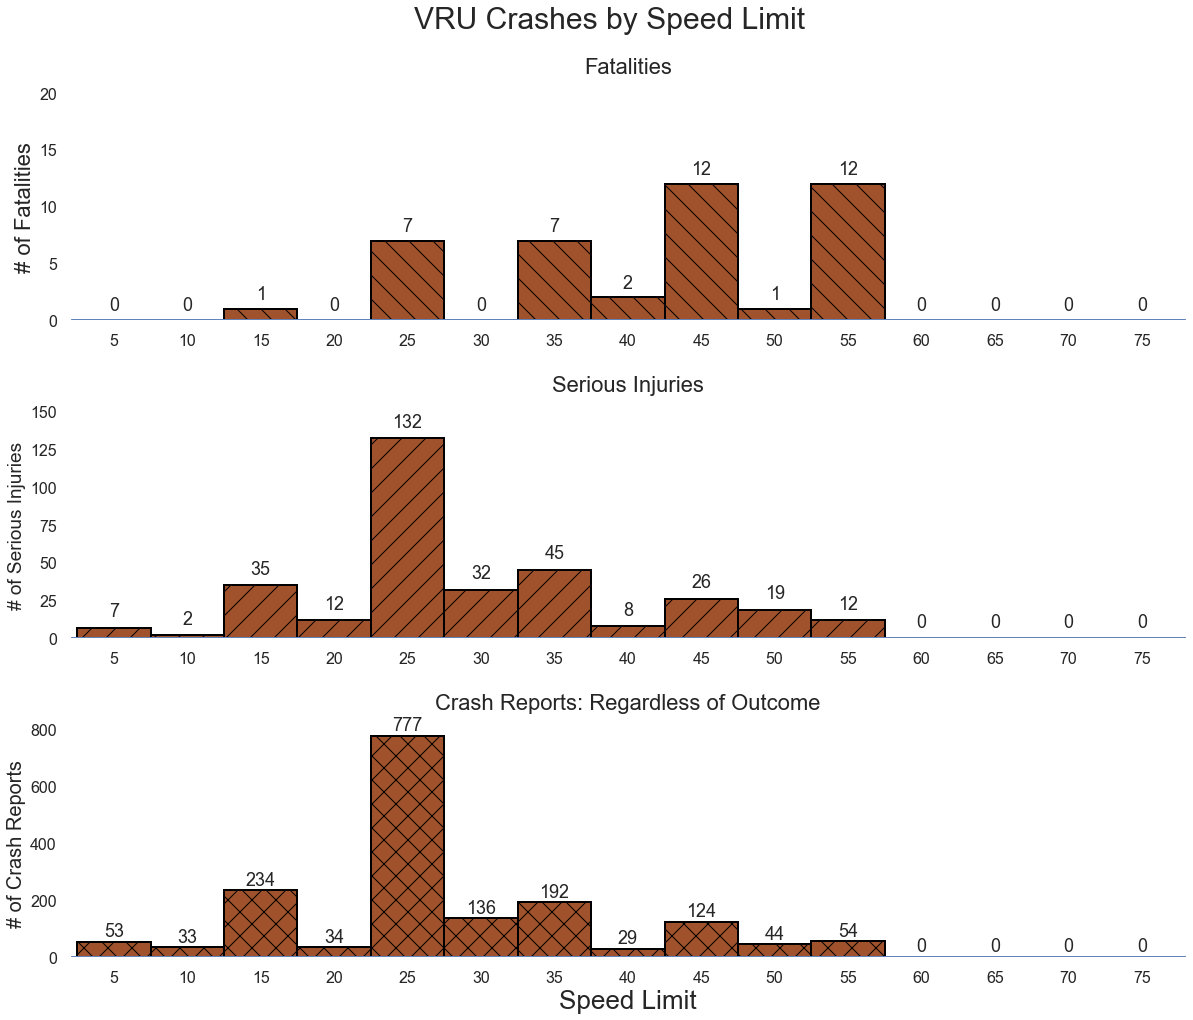

In [5]:
# set up main figure with three subplots
plt.style.use('seaborn')
sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
fig, ax = plt.subplots(3,1,figsize=(20,15))
tick_spacing = 5
fig.suptitle('VRU Crashes by Speed Limit', fontsize=30)

# subplot data
ax[0].bar(speed_list, vru_fatalities, width = 5, hatch = "\\", color = 'sienna', edgecolor = "black", linewidth=2)
ax[1].bar(speed_list, vru_serious_injuries, width = 5, hatch = "/", color = 'sienna', edgecolor = "black", linewidth=2)
ax[2].bar(speed_list, vru_crashes, width = 5, hatch = "x", color = 'sienna', edgecolor = "black", linewidth=2)

# annotate all plots with bar totals
rects = ax[0].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[0].text(rect.get_x() + rect.get_width() / 2, height + 0.5, label, ha="center", va="bottom",fontsize=18)

rects = ax[1].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[1].text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha="center", va="bottom",fontsize=18)

rects = ax[2].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[2].text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha="center", va="bottom",fontsize=18)

# format each subplot
ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
ax[0].set_ylim([0, 20])
ax[0].set_xlim([2, 78])
ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
ax[0].tick_params(axis='x', which='major', labelsize=16)
ax[0].tick_params(axis='y', which='major', labelsize=16)
ax[0].tick_params(axis='both', which='minor', labelsize=8)

ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
ax[1].set_ylim([0, 150])
ax[1].set_xlim([2, 78])
ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
ax[1].tick_params(axis='x', which='major', labelsize=16)
ax[1].tick_params(axis='y', which='major', labelsize=16)
ax[1].tick_params(axis='both', which='minor', labelsize=8)

ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
ax[2].set_ylim([0, 800])
ax[2].set_xlim([2, 78])
ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
ax[2].tick_params(axis='x', which='major', labelsize=16)
ax[2].tick_params(axis='y', which='major', labelsize=16)
ax[2].tick_params(axis='both', which='minor', labelsize=8)

# set the spacing between subplots
plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

plt.show()

## Figure 4: VRU Crashes at Crosswalks

In [7]:
crosswalks = ['Crosswalk','Outside a Crosswalk']
vru = analysis_2024.loc[analysis_2024['VRU']==1]
vru_crosswalk_fatalities = []
vru_crosswalk_serious_injuries = []
vru_crosswalk_crashes = []

for i in crosswalks:
    num_vru_crosswalk_fatalities = vru.loc[vru[i]==1]['Fatality'].sum()
    vru_crosswalk_fatalities.append(num_vru_crosswalk_fatalities)
    num_vru_crosswalk_serious_injuries = vru.loc[vru[i]==1]['Incapacitating Injury'].sum()
    vru_crosswalk_serious_injuries.append(num_vru_crosswalk_serious_injuries)
    num_vru_crosswalk_crashes = vru.loc[vru[i]==1].shape[0]
    vru_crosswalk_crashes.append(num_vru_crosswalk_crashes)

<ipython-input-10-b6186f403c0e>:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


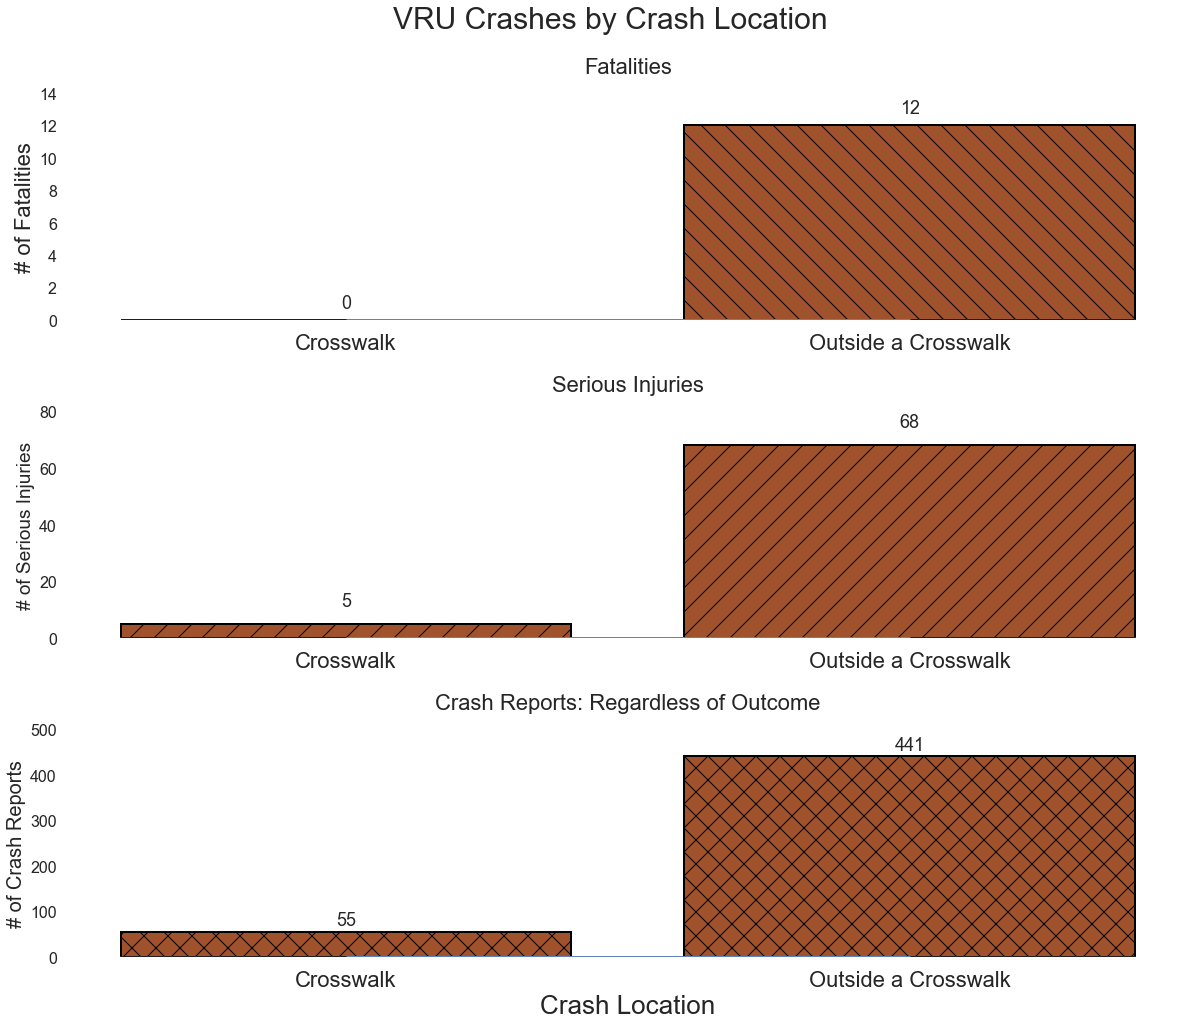

In [10]:
# set up main figure with three subplots
plt.style.use('seaborn')
sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
fig, ax = plt.subplots(3,1,figsize=(20,15))
fig.suptitle('VRU Crashes by Crash Location', fontsize=30)

# subplot data
ax[0].bar(crosswalks, vru_crosswalk_fatalities, hatch = "\\", color = 'sienna', edgecolor = "black", linewidth=2)
ax[1].bar(crosswalks, vru_crosswalk_serious_injuries, hatch = "/", color = 'sienna', edgecolor = "black", linewidth=2)
ax[2].bar(crosswalks, vru_crosswalk_crashes, hatch = "x", color = 'sienna', edgecolor = "black", linewidth=2)

# annotate all plots with bar totals
rects = ax[0].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[0].text(rect.get_x() + rect.get_width() / 2, height + 0.5, label, ha="center", va="bottom",fontsize=18)

rects = ax[1].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[1].text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha="center", va="bottom",fontsize=18)

rects = ax[2].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[2].text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha="center", va="bottom",fontsize=18)

# format each subplot
ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
ax[0].set_ylim([0, 14])
ax[0].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
ax[0].tick_params(axis='x', which='major', labelsize=22)
ax[0].tick_params(axis='y', which='major', labelsize=16)
ax[0].tick_params(axis='both', which='minor', labelsize=8)

ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
ax[1].set_ylim([0, 80])
ax[1].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
ax[1].tick_params(axis='x', which='major', labelsize=22)
ax[1].tick_params(axis='y', which='major', labelsize=16)
ax[1].tick_params(axis='both', which='minor', labelsize=8)

ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
ax[2].set_ylim([0, 500])
ax[2].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
ax[2].set_xlabel('Crash Location',fontsize = 26) #xlabel
ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
ax[2].tick_params(axis='x', which='major', labelsize=22)
ax[2].tick_params(axis='y', which='major', labelsize=16)
ax[2].tick_params(axis='both', which='minor', labelsize=8)

# set the spacing between subplots
plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

plt.show()

## Figure 5: Wildlife Crashes By Speed Limit

In [11]:
speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
animal = analysis_2024.loc[analysis_2024['Involving Animal']==1]
animal_fatalities = []
animal_serious_injuries = []
animal_crashes = []

for i in speed_columns:
    num_animal_fatalities = animal.loc[animal[i]==1]['Fatality'].sum()
    animal_fatalities.append(num_animal_fatalities)
    num_animal_serious_injuries = animal.loc[animal[i]==1]['Incapacitating Injury'].sum()
    animal_serious_injuries.append(num_animal_serious_injuries)    
    num_animal_crashes = animal.loc[animal[i]==1].shape[0]
    animal_crashes.append(num_animal_crashes)

<ipython-input-13-70c0e3630b9f>:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


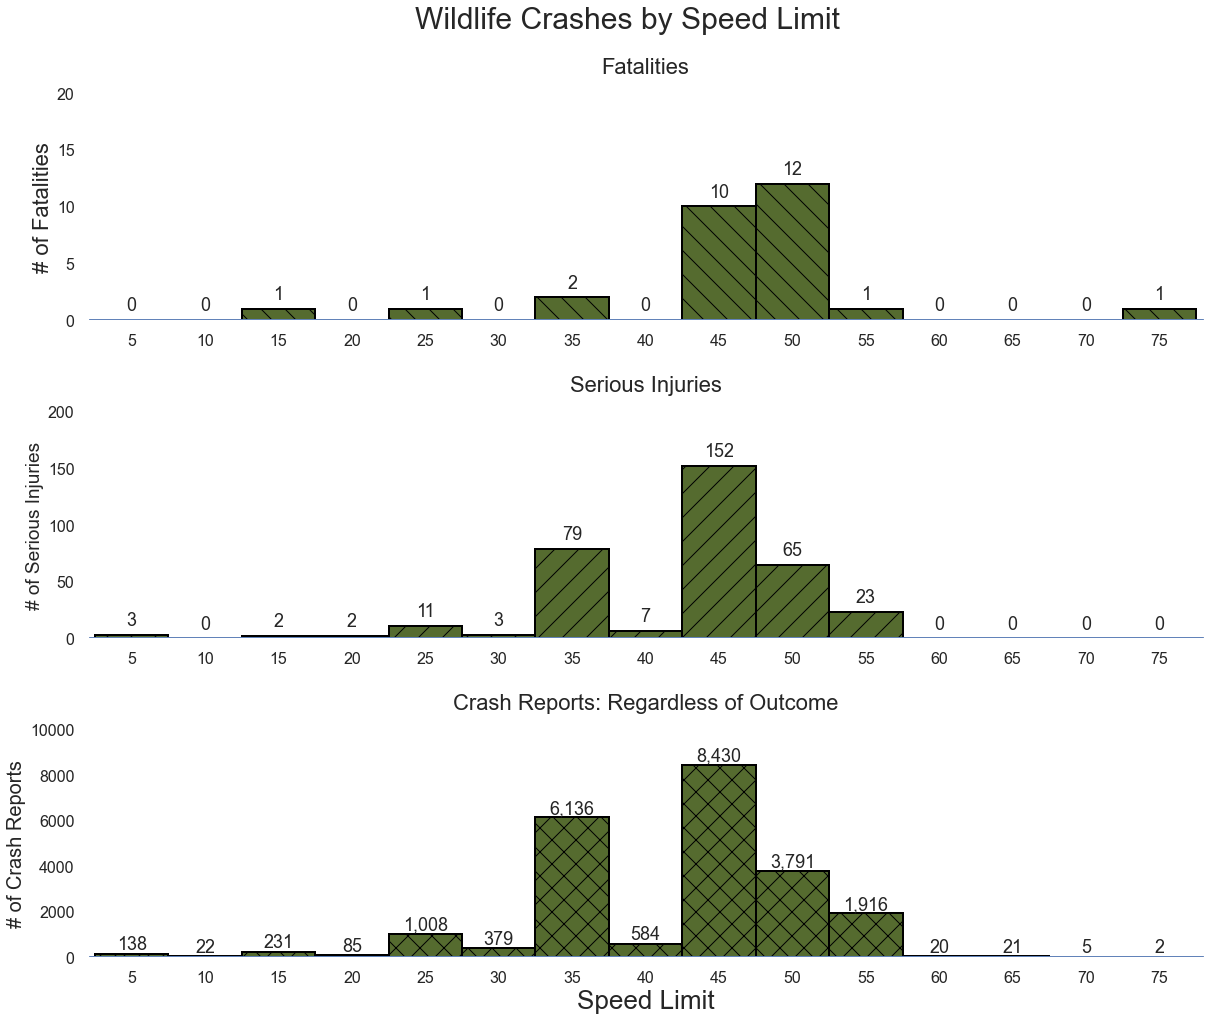

In [13]:
# set up main figure with three subplots
plt.style.use('seaborn')
sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
fig, ax = plt.subplots(3,1,figsize=(20,15))
tick_spacing = 5
fig.suptitle('Wildlife Crashes by Speed Limit', fontsize=30)

# subplot data
ax[0].bar(speed_list, animal_fatalities, width = 5, hatch = "\\", color = 'darkolivegreen', edgecolor = "black", linewidth=2)
ax[1].bar(speed_list, animal_serious_injuries, width = 5, hatch = "/", color = 'darkolivegreen', edgecolor = "black", linewidth=2)
ax[2].bar(speed_list, animal_crashes, width = 5, hatch = "x", color = 'darkolivegreen', edgecolor = "black", linewidth=2)

# annotate all plots with bar totals
rects = ax[0].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[0].text(rect.get_x() + rect.get_width() / 2, height + 0.5, label, ha="center", va="bottom",fontsize=18)

rects = ax[1].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[1].text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha="center", va="bottom",fontsize=18)

rects = ax[2].patches
labels = [f"label{i}" for i in range(len(rects))]
for rect, label in zip(rects, labels):
    height = rect.get_height()
    label = '{:,}'.format(int(height))
    ax[2].text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha="center", va="bottom",fontsize=18)

# format each subplot
ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
ax[0].set_ylim([0, 20])
ax[0].set_xlim([2, 78])
ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
ax[0].tick_params(axis='x', which='major', labelsize=16)
ax[0].tick_params(axis='y', which='major', labelsize=16)
ax[0].tick_params(axis='both', which='minor', labelsize=8)

ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
ax[1].set_ylim([0, 200])
ax[1].set_xlim([2, 78])
ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
ax[1].tick_params(axis='x', which='major', labelsize=16)
ax[1].tick_params(axis='y', which='major', labelsize=16)
ax[1].tick_params(axis='both', which='minor', labelsize=8)

ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
ax[2].set_ylim([0, 10000])
ax[2].set_xlim([2, 78])
ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
ax[2].tick_params(axis='x', which='major', labelsize=16)
ax[2].tick_params(axis='y', which='major', labelsize=16)
ax[2].tick_params(axis='both', which='minor', labelsize=8)

# set the spacing between subplots
plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

plt.show()

## Data Quality Figures

## Figure 7: Serious Injury Crash Data Quality

In [4]:
goodyears = analysis_2024.loc[analysis_2024['YEAR'].isin(range(1988,2025))]
goodyears['YEAR'].value_counts().sort_index()

YEAR
1988.0        2
1989.0     6698
1990.0    10995
1991.0    10541
1992.0    10862
1993.0    11481
1994.0    11185
1995.0    10959
1996.0    11145
1997.0    11159
1998.0     7321
1999.0     7577
2000.0     7406
2001.0     9270
2002.0     6949
2003.0     9014
2004.0     6925
2005.0     7230
2006.0     3225
2007.0     3320
2008.0     4331
2009.0     4222
2010.0     4217
2011.0     3997
2012.0     2894
2013.0     1785
2014.0     1606
2015.0      573
2016.0      881
2017.0      939
2018.0     3642
2019.0     4012
2020.0     2887
2021.0     3442
2022.0     3611
2023.0     4131
2024.0      729
Name: count, dtype: int64

In [12]:
imars_all_year = goodyears.loc[goodyears['database']=="IMARS"].groupby('YEAR')
imars_all_year_injuries = imars_all_year['Incapacitating Injury'].sum()
cds_all_year = goodyears.loc[goodyears['database']=="CDS"].groupby('YEAR')
cds_all_year_injuries = cds_all_year['Incapacitating Injury'].sum()
goodyears_coords = goodyears.loc[goodyears['LATITUDE'].notnull()]
imars_coords_year = goodyears_coords.loc[goodyears_coords['database']=="IMARS"].groupby('YEAR')
imars_coords_year_injuries = imars_coords_year['Incapacitating Injury'].sum()
cds_coords_year = goodyears_coords.loc[goodyears_coords['database']=="CDS"].groupby('YEAR')
cds_coords_year_injuries = cds_coords_year['Incapacitating Injury'].sum()

<ipython-input-16-8fae8515beb7>:1: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


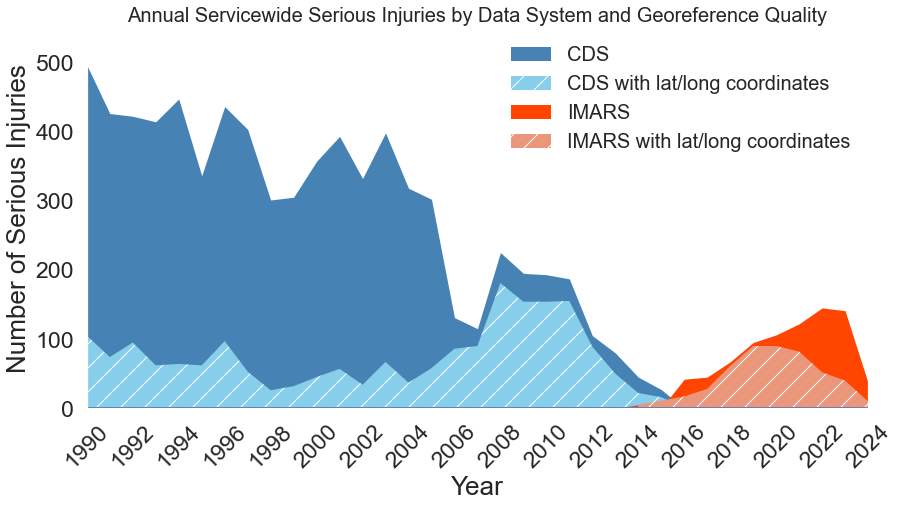

In [16]:
plt.style.use('seaborn')
tick_spacing = 2 
sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
fig,ax = plt.subplots(1,1, figsize=(14, 7))

ax.set_title('Annual Servicewide Serious Injuries by Data System and Georeference Quality', fontsize=20)
ax.fill_between(cds_all_year_injuries.index, cds_all_year_injuries, label = 'CDS', facecolor = "steelblue")
ax.fill_between(cds_coords_year_injuries.index, cds_coords_year_injuries, label = 'CDS with lat/long coordinates', hatch = '/', facecolor = "skyblue")
ax.fill_between(imars_all_year_injuries.index, imars_all_year_injuries, label = 'IMARS', facecolor = "orangered")
ax.fill_between(imars_coords_year_injuries.index, imars_coords_year_injuries, label = 'IMARS with lat/long coordinates', hatch = "/", facecolor = "darksalmon")

legend = plt.legend(frameon = 2,fontsize=20)
frame = legend.get_frame()
frame.set_color('white')
frame.set_facecolor('white')
frame.set_edgecolor('black')
plt.xlim([1990,2024])
plt.ylim([0,550])
ax.grid('off')
ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax.tick_params(axis='x', which='major', labelsize=23, rotation=45)
ax.tick_params(axis='y', which='major', labelsize=23)
ax.tick_params(axis='both', which='minor', labelsize=23)
ax.hlines(0, xmin = 1990, xmax = 2024, linewidth = 3)
ax.set_xlabel("Year", fontsize=26)
ax.set_ylabel("Number of Serious Injuries", fontsize=26)

plt.show()

## Figure 8: Fatal Crash Data Quality

In [21]:
imars_all_year = goodyears.loc[goodyears['database']=="IMARS"].groupby('YEAR')
imars_all_year_fatalities = imars_all_year['Fatality'].sum()
cds_all_year = goodyears.loc[goodyears['database']=="CDS"].groupby('YEAR')
cds_all_year_fatalities = cds_all_year['Fatality'].sum()
goodyears_coords = goodyears.loc[goodyears['LATITUDE'].notnull()]
imars_coords_year = goodyears_coords.loc[goodyears_coords['database']=="IMARS"].groupby('YEAR')
imars_coords_year_fatalities = imars_coords_year['Fatality'].sum()
cds_coords_year = goodyears_coords.loc[goodyears_coords['database']=="CDS"].groupby('YEAR')
cds_coords_year_fatalities = cds_coords_year['Fatality'].sum()

<ipython-input-22-577b281cb82f>:1: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


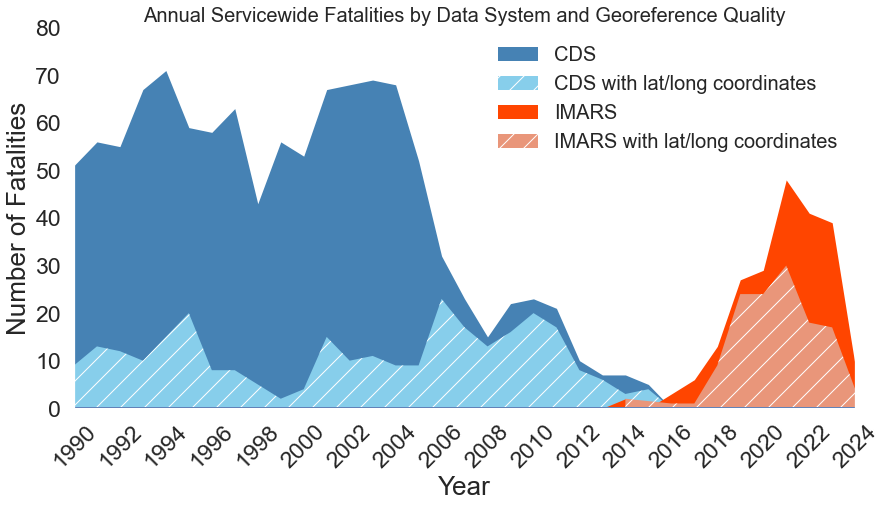

In [22]:
plt.style.use('seaborn')
tick_spacing = 2 
sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
fig,ax = plt.subplots(1,1, figsize=(14, 7))

ax.set_title('Annual Servicewide Fatalities by Data System and Georeference Quality', fontsize=20)
ax.fill_between(cds_all_year_fatalities.index, cds_all_year_fatalities, label = 'CDS', facecolor = "steelblue")
ax.fill_between(cds_coords_year_fatalities.index, cds_coords_year_fatalities, label = 'CDS with lat/long coordinates', hatch = '/', facecolor = "skyblue")
ax.fill_between(imars_all_year_fatalities.index, imars_all_year_fatalities, label = 'IMARS', facecolor = "orangered")
ax.fill_between(imars_coords_year_fatalities.index, imars_coords_year_fatalities, label = 'IMARS with lat/long coordinates', hatch = "/", facecolor = "darksalmon")

legend = plt.legend(frameon = 2,fontsize=20)
frame = legend.get_frame()
frame.set_color('white')
frame.set_facecolor('white')
frame.set_edgecolor('black')
plt.xlim([1990,2024])
plt.ylim([0,80])
ax.set_yticks([0,10,20,30,40,50,60,70,80])
ax.grid('off')
ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
ax.tick_params(axis='x', which='major', labelsize=23, rotation=45)
ax.tick_params(axis='y', which='major', labelsize=23)
ax.tick_params(axis='both', which='minor', labelsize=23)
ax.hlines(0, xmin = 1990, xmax = 2024, linewidth = 3)
ax.set_xlabel("Year", fontsize=26)
ax.set_ylabel("Number of Fatalities", fontsize=26)

plt.show()

## Figure 9: IMARS Geolocation Quality

In [7]:
df = pd.read_excel("./Final Coordinate Stats.xlsx")
df.columns=["Park","Region","Within Boundary","<1mi Out","1-10mi Out","10-100mi Out",">100mi Out","No Coordinates","Total Crashes"]
df = df.sort_values(by="Total Crashes", ascending=False)
top10 = pd.DataFrame(df.head(10)) # 10 parks with the most crashes servicewide 
top10

,Park,Region,Within Boundary,<1mi Out,1-10mi Out,10-100mi Out,>100mi Out,No Coordinates,Total Crashes
176,GRSM,SER,720,19,2,8,49,922,1720
416,YOSE,PWR,442,12,6,4,17,1201,1682
415,YELL,IMR,547,5,7,0,81,1008,1648
36,BLRI,SER,656,33,10,20,10,824,1553
182,GWMP,NCR,844,282,22,20,3,326,1497
281,NATR,SER,571,24,29,93,54,710,1481
329,ROCR,NCR,70,106,225,7,6,134,548
171,GRCA,IMR,114,1,2,1,20,362,500
235,LAKE,PWR,328,0,6,1,8,84,427
107,DEWA,NER,153,6,0,2,4,241,406


In [8]:
# determine proportion of total crashes for plotting 100% stacked bars
top10['Within Boundary'] = top10['Within Boundary']/top10['Total Crashes']
top10["<1mi Out"] = top10["<1mi Out"]/top10['Total Crashes']
top10["1-10mi Out"] = top10["1-10mi Out"]/top10['Total Crashes']
top10["10-100mi Out"] = top10["10-100mi Out"]/top10['Total Crashes']
top10[">100mi Out"] = top10[">100mi Out"]/top10['Total Crashes']
top10["No Coordinates"] = top10["No Coordinates"]/top10['Total Crashes']

# check that each row sums to 1
top10['sum'] = top10['Within Boundary'] + top10["<1mi Out"] + top10["1-10mi Out"] + top10["10-100mi Out"] + top10[">100mi Out"] + top10["No Coordinates"]
top10

,Park,Region,Within Boundary,<1mi Out,1-10mi Out,10-100mi Out,>100mi Out,No Coordinates,Total Crashes,sum
176,GRSM,SER,0.418605,0.011047,0.001163,0.004651,0.028488,0.536047,1720,1.0
416,YOSE,PWR,0.262782,0.007134,0.003567,0.002378,0.010107,0.714031,1682,1.0
415,YELL,IMR,0.331917,0.003034,0.004248,0.000000,0.049150,0.611650,1648,1.0
36,BLRI,SER,0.422408,0.021249,0.006439,0.012878,0.006439,0.530586,1553,1.0
182,GWMP,NCR,0.563794,0.188377,0.014696,0.013360,0.002004,0.217769,1497,1.0
281,NATR,SER,0.385550,0.016205,0.019581,0.062795,0.036462,0.479406,1481,1.0
329,ROCR,NCR,0.127737,0.193431,0.410584,0.012774,0.010949,0.244526,548,1.0
171,GRCA,IMR,0.228000,0.002000,0.004000,0.002000,0.040000,0.724000,500,1.0
235,LAKE,PWR,0.768150,0.000000,0.014052,0.002342,0.018735,0.196721,427,1.0
107,DEWA,NER,0.376847,0.014778,0.000000,0.004926,0.009852,0.593596,406,1.0


In [9]:
top10_slim = top10.drop(columns=['Park','Region','Total Crashes','sum'])

<ipython-input-10-1760841f6413>:23: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


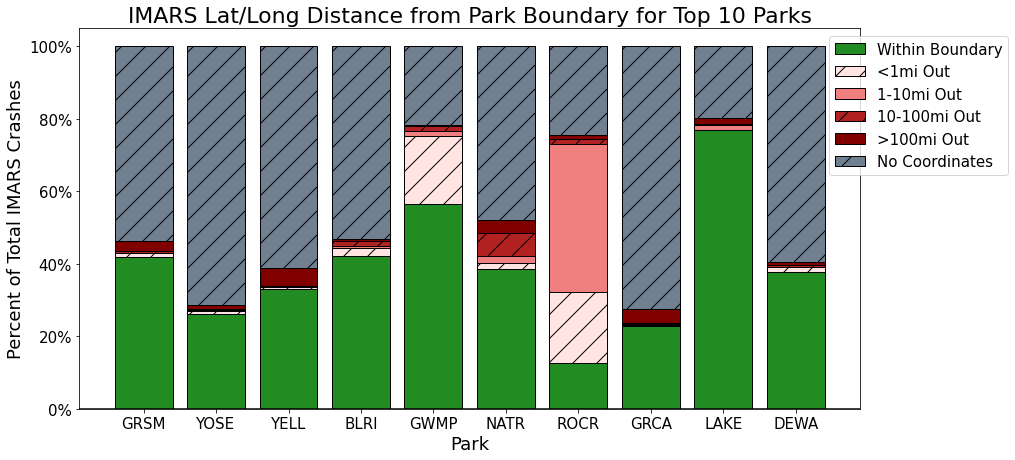

In [10]:
import matplotlib.patches as mpatches

fig,ax = plt.subplots(1,1, figsize=(14, 7))
# Each column will take the sum of all columns before it as its base
bottom_list = []

for i in top10_slim.columns:
    b = list(top10_slim.loc[:, top10_slim.columns[0]: i].sum(axis=1))
    bottom_list.append(b)

x_ax = top10['Park']
patterns = ['','/','','/','','/'] # define hatch for each bin
colorlist = ['forestgreen','mistyrose', 'lightcoral', 'firebrick', 'maroon', 'slategrey'] # define color for each bin
for i, v in enumerate(top10_slim.columns):
    if i == 0:
        # First column is at the bottom of the chart so bottom is 0 and doesn't need to be specified.
        plt.bar(x_ax, top10_slim[v], hatch=patterns[i], color=colorlist[i], edgecolor='k')
    else:
        plt.bar(x_ax, top10_slim[v], bottom=bottom_list[i - 1], hatch=patterns[i], color=colorlist[i], edgecolor='k')

ax.tick_params(axis='x', which='major', labelsize=15)
y_vals = ax.get_yticks()
ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)
ax.set_ylabel("Percent of Total IMARS Crashes", fontsize=18)
ax.set_xlabel("Park", fontsize=18)
ax.axhline(y=0, color='k')

within_patch = mpatches.Patch(hatch=patterns[0], facecolor=colorlist[0], edgecolor="black", label=top10_slim.columns[0])
one_mile_patch = mpatches.Patch(hatch=patterns[1], facecolor=colorlist[1], edgecolor="black", label=top10_slim.columns[1])
ten_mile_patch = mpatches.Patch(hatch=patterns[2], facecolor=colorlist[2], edgecolor="black", label=top10_slim.columns[2])
hundred_mile_patch = mpatches.Patch(hatch=patterns[3], facecolor=colorlist[3], edgecolor="black", label=top10_slim.columns[3])
over_hundred_mile_patch = mpatches.Patch(hatch=patterns[4], facecolor=colorlist[4], edgecolor="black", label=top10_slim.columns[4])
no_coords_patch = mpatches.Patch(hatch=patterns[5], facecolor=colorlist[5], edgecolor="black", label=top10_slim.columns[5])
ax.legend(loc="upper left", frameon=1,bbox_to_anchor=(0.95, 1), prop={'size': 15}, handles = [within_patch, one_mile_patch, ten_mile_patch, hundred_mile_patch, over_hundred_mile_patch, no_coords_patch])
ax.set_title('IMARS Lat/Long Distance from Park Boundary for Top 10 Parks', fontsize=22)

plt.show()